In [2]:
from google.colab import files

uploaded = files.upload()

Saving ml-latest-small.zip to ml-latest-small.zip


In [3]:
import zipfile
import os

zip_file = "ml-latest-small.zip"

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall(".")

print("Dataset extracted successfully.")
print(os.listdir("ml-latest-small"))

Dataset extracted successfully.
['movies.csv', 'tags.csv', 'links.csv', 'ratings.csv', 'README.txt']


In [4]:
import pandas as pd
import numpy as np

data_folder = "ml-latest-small"

movies = pd.read_csv(f"{data_folder}/movies.csv")
ratings = pd.read_csv(f"{data_folder}/ratings.csv")
tags = pd.read_csv(f"{data_folder}/tags.csv")
links = pd.read_csv(f"{data_folder}/links.csv")

print("All files loaded successfully.")
print("Movies:", movies.shape)
print("Ratings:", ratings.shape)
print("Tags:", tags.shape)
print("Links:", links.shape)

All files loaded successfully.
Movies: (9742, 3)
Ratings: (100836, 4)
Tags: (3683, 4)
Links: (9742, 3)


In [5]:
print("MOVIES")
display(movies.head())

print("RATINGS")
display(ratings.head())

print("Missing values in each file:")
print("Movies:\n", movies.isnull().sum())
print("Ratings:\n", ratings.isnull().sum())

print("Duplicate rows:")
print("Movies:", movies.duplicated().sum())
print("Ratings:", ratings.duplicated().sum())

MOVIES


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


RATINGS


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


Missing values in each file:
Movies:
 movieId    0
title      0
genres     0
dtype: int64
Ratings:
 userId       0
movieId      0
rating       0
timestamp    0
dtype: int64
Duplicate rows:
Movies: 0
Ratings: 0


In [6]:
datasets = {
    "Movies": movies,
    "Ratings": ratings,
    "Tags": tags,
    "Links": links
}

for name, df in datasets.items():
    print(f"\n--- {name} ---")
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())

print("\nRating distribution:")
print(ratings["rating"].value_counts().sort_index())

print("\nUnique users:", ratings["userId"].nunique())
print("Unique rated movies:", ratings["movieId"].nunique())
print("Unique genres:", len(set(
    genre
    for genres in movies["genres"]
    for genre in genres.split("|")
    if genre != "(no genres listed)"
)))

print("\nMovies with no listed genres:",
      (movies["genres"] == "(no genres listed)").sum())


--- Movies ---
Missing values: 0
Duplicate rows: 0

--- Ratings ---
Missing values: 0
Duplicate rows: 0

--- Tags ---
Missing values: 0
Duplicate rows: 0

--- Links ---
Missing values: 8
Duplicate rows: 0

Rating distribution:
rating
0.5     1370
1.0     2811
1.5     1791
2.0     7551
2.5     5550
3.0    20047
3.5    13136
4.0    26818
4.5     8551
5.0    13211
Name: count, dtype: int64

Unique users: 610
Unique rated movies: 9724
Unique genres: 19

Movies with no listed genres: 34


In [7]:
ratings_ml = ratings.copy()
movies_ml = movies.copy()

ratings_ml["liked"] = (
    ratings_ml["rating"] >= 4.0
).astype(int)

all_genres = sorted({
    genre
    for genre_list in movies_ml["genres"]
    for genre in genre_list.split("|")
    if genre != "(no genres listed)"
})

for genre in all_genres:
    movies_ml[genre] = movies_ml["genres"].apply(
        lambda x: int(genre in x.split("|"))
    )

print("Like labels created.")
print("\nTarget distribution:")
print(ratings_ml["liked"].value_counts())
print("\nGenre columns created:", len(all_genres))

display(movies_ml.head())
display(ratings_ml.head())

Like labels created.

Target distribution:
liked
0    52256
1    48580
Name: count, dtype: int64

Genre columns created: 19


,movieId,title,genres,Action,Adventure,Animation,Children,Comedy,Crime,Documentary,...,Film-Noir,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,0,1,1,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2,Jumanji (1995),Adventure|Children|Fantasy,0,1,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,3,Grumpier Old Men (1995),Comedy|Romance,0,0,0,0,1,0,0,...,0,0,0,0,0,1,0,0,0,0
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,0,0,0,0,1,0,0,...,0,0,0,0,0,1,0,0,0,0
4,5,Father of the Bride Part II (1995),Comedy,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0


,userId,movieId,rating,timestamp,liked
0,1,1,4.0,964982703,1
1,1,3,4.0,964981247,1
2,1,6,4.0,964982224,1
3,1,47,5.0,964983815,1
4,1,50,5.0,964982931,1


In [17]:
from sklearn.model_selection import train_test_split

model_data = ratings_ml[
    ["userId", "movieId", "rating", "liked"]
].copy()

train_data, test_data = train_test_split(
    model_data,
    test_size=0.20,
    random_state=42,
    stratify=model_data["liked"]
)

print("Training rows:", len(train_data))
print("Testing rows:", len(test_data))

print("\nTraining target distribution:")
print(train_data["liked"].value_counts())

print("\nTesting target distribution:")
print(test_data["liked"].value_counts())

Training rows: 80668
Testing rows: 20168

Training target distribution:
liked
0    41804
1    38864
Name: count, dtype: int64

Testing target distribution:
liked
0    10452
1     9716
Name: count, dtype: int64


In [18]:
genre_columns = all_genres

X_train_raw = train_data[
    ["userId", "movieId", "rating"]
].merge(
    movies_ml[["movieId"] + genre_columns],
    on="movieId",
    how="left"
)

y_train = train_data["liked"].copy()

X_test_raw = test_data[
    ["userId", "movieId"]
].merge(
    movies_ml[["movieId"] + genre_columns],
    on="movieId",
    how="left"
)

y_test = test_data["liked"].copy()

print("Number of input features:", len(genre_columns) + 6)

print("Training data shape:", X_train_raw.shape)
print("Testing data shape:", X_test_raw.shape)

print("Missing training values:", X_train_raw.isnull().sum().sum())
print("Missing testing values:", X_test_raw.isnull().sum().sum())

print("\nTraining labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Number of input features: 25
Training data shape: (80668, 22)
Testing data shape: (20168, 21)
Missing training values: 0
Missing testing values: 0

Training labels: (80668,)
Testing labels: (20168,)


In [20]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import StratifiedKFold

class LeakageSafeMovieFeatures(BaseEstimator, TransformerMixin):

    def __init__(self, genre_columns, n_splits=5, random_state=42):
        self.genre_columns = genre_columns
        self.n_splits = n_splits
        self.random_state = random_state

    def calculate_stats(self, X, y):

        data = pd.DataFrame({
            "userId": X["userId"].values,
            "movieId": X["movieId"].values,
            "rating": X["rating"].values,
            "liked": np.asarray(y)
        })

        user_stats = data.groupby("userId").agg(
            user_avg_rating=("rating", "mean"),
            user_rating_count=("rating", "count"),
            user_like_rate=("liked", "mean")
        )

        movie_stats = data.groupby("movieId").agg(
            movie_avg_rating=("rating", "mean"),
            movie_rating_count=("rating", "count"),
            movie_like_rate=("liked", "mean")
        )

        return (
            user_stats,
            movie_stats,
            data["rating"].mean(),
            data["liked"].mean()
        )

    def make_features(self, X, user_stats, movie_stats,
                      global_rating, global_like):

        data = X[["userId", "movieId"] + self.genre_columns].copy()

        data["user_avg_rating"] = data["userId"].map(
            user_stats["user_avg_rating"]
        ).fillna(global_rating)

        data["user_rating_count"] = data["userId"].map(
            user_stats["user_rating_count"]
        ).fillna(0)

        data["user_like_rate"] = data["userId"].map(
            user_stats["user_like_rate"]
        ).fillna(global_like)

        data["movie_avg_rating"] = data["movieId"].map(
            movie_stats["movie_avg_rating"]
        ).fillna(global_rating)

        data["movie_rating_count"] = data["movieId"].map(
            movie_stats["movie_rating_count"]
        ).fillna(0)

        data["movie_like_rate"] = data["movieId"].map(
            movie_stats["movie_like_rate"]
        ).fillna(global_like)

        feature_columns = [
            "user_avg_rating",
            "user_rating_count",
            "user_like_rate",
            "movie_avg_rating",
            "movie_rating_count",
            "movie_like_rate"
        ] + self.genre_columns

        return data[feature_columns]

    def fit(self, X, y):
        (
            self.user_stats_,
            self.movie_stats_,
            self.global_rating_,
            self.global_like_
        ) = self.calculate_stats(X, y)

        return self

    def transform(self, X):

        return self.make_features(
            X,
            self.user_stats_,
            self.movie_stats_,
            self.global_rating_,
            self.global_like_
        )

    def fit_transform(self, X, y=None, **fit_params):

        self.fit(X, y)

        y_array = np.asarray(y)

        cv = StratifiedKFold(
            n_splits=self.n_splits,
            shuffle=True,
            random_state=self.random_state
        )

        feature_columns = [
            "user_avg_rating",
            "user_rating_count",
            "user_like_rate",
            "movie_avg_rating",
            "movie_rating_count",
            "movie_like_rate"
        ] + self.genre_columns

        oof_features = pd.DataFrame(
            np.zeros((len(X), len(feature_columns))),
            columns=feature_columns,
            index=X.index
        )

        for train_idx, valid_idx in cv.split(X, y_array):

            fold_train = X.iloc[train_idx]
            fold_y = y_array[train_idx]

            user_stats, movie_stats, global_rating, global_like = (
                self.calculate_stats(fold_train, fold_y)
            )

            fold_features = self.make_features(
                X.iloc[valid_idx],
                user_stats,
                movie_stats,
                global_rating,
                global_like
            )

            oof_features.iloc[valid_idx] = fold_features.to_numpy()

        return oof_features

In [24]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

models = {
    "Logistic Regression": Pipeline([
        ("features", LeakageSafeMovieFeatures(genre_columns)),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ]),

    "KNN": Pipeline([
        ("features", LeakageSafeMovieFeatures(genre_columns)),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Random Forest": Pipeline([
        ("features", LeakageSafeMovieFeatures(genre_columns)),
        ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("features", LeakageSafeMovieFeatures(genre_columns)),
        ("model", GradientBoostingClassifier(random_state=42))
    ])
}

for name, model in models.items():
    print(f"\nTraining {name}...")
    model.fit(X_train_raw, y_train)

print("\nAll four models trained successfully!")


Training Logistic Regression...

Training KNN...

Training Random Forest...

Training Gradient Boosting...

All four models trained successfully!


In [25]:
from IPython.display import display as show_table

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

for name, model in models.items():

    predictions = model.predict(X_test_raw)
    probabilities = model.predict_proba(X_test_raw)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")

show_table(
    results_df.sort_values(
        by="F1 Score",
        ascending=False
    ).round(4)
)

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
3,Gradient Boosting,0.7152,0.6961,0.7255,0.7105,0.7891
2,Random Forest,0.7110,0.6969,0.7081,0.7025,0.7831
0,Logistic Regression,0.7091,0.6949,0.7063,0.7005,0.7819
1,KNN,0.6763,0.6640,0.6644,0.6642,0.7280


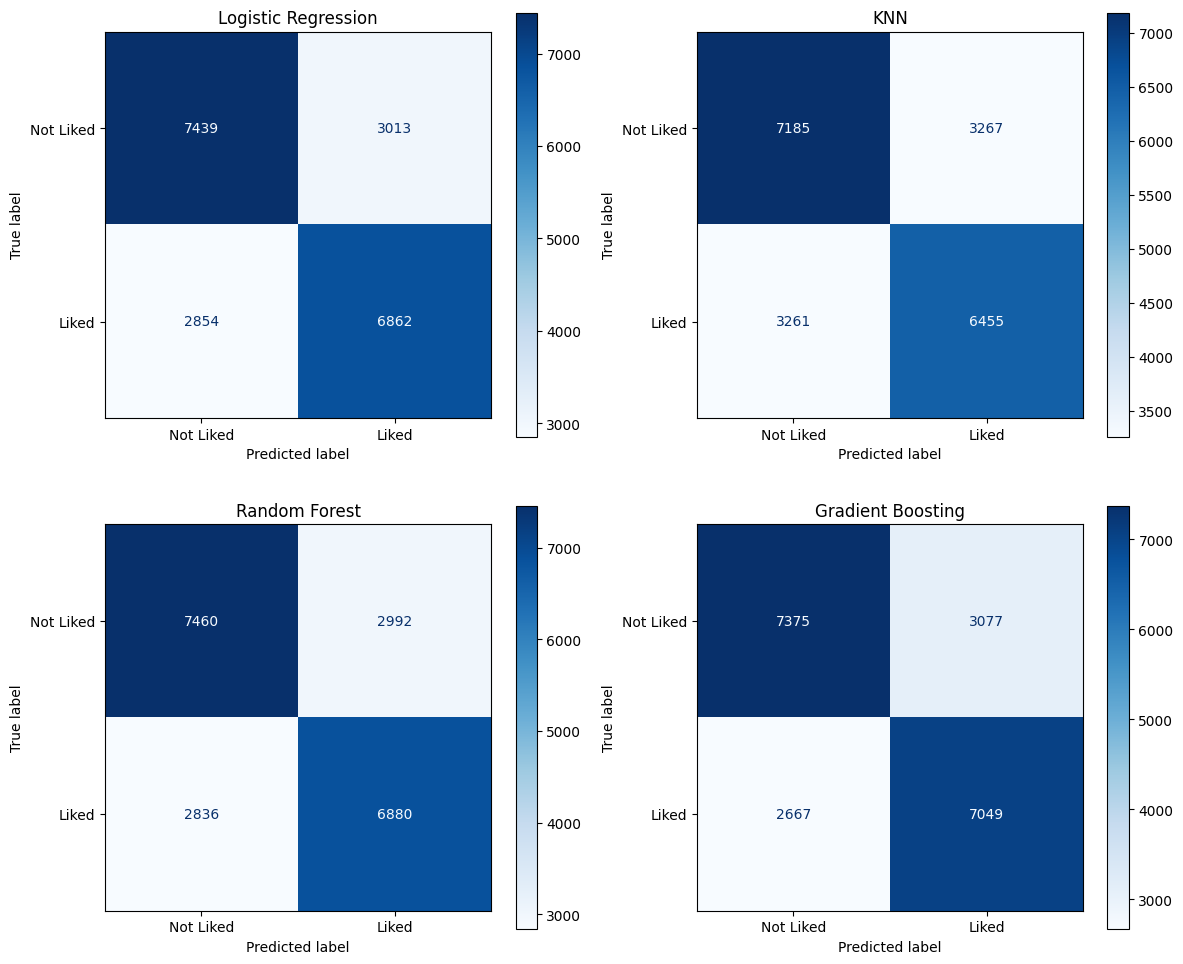

In [26]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, model) in zip(axes.flatten(), models.items()):

    predictions = model.predict(X_test_raw)

    cm = confusion_matrix(y_test, predictions)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Not Liked", "Liked"]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d"
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

In [27]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    "model__n_estimators": [100, 150, 200],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_depth": [2, 3, 4],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__subsample": [0.8, 1.0]
}

random_search = RandomizedSearchCV(
    estimator=models["Gradient Boosting"],
    param_distributions=param_grid,
    n_iter=10,
    scoring="f1",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train_raw, y_train)

tuned_model = random_search.best_estimator_

print("\nBest Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(round(random_search.best_score_, 4))

Fitting 3 folds for each of 10 candidates, totalling 30 fits

Best Parameters:
{'model__subsample': 1.0, 'model__n_estimators': 200, 'model__min_samples_split': 10, 'model__min_samples_leaf': 4, 'model__max_depth': 3, 'model__learning_rate': 0.1}

Best Cross-Validation F1 Score:
0.7059


In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

tuned_predictions = tuned_model.predict(X_test_raw)
tuned_probabilities = tuned_model.predict_proba(X_test_raw)[:, 1]

tuned_results = {
    "Model": "Tuned Gradient Boosting",
    "Accuracy": accuracy_score(y_test, tuned_predictions),
    "Precision": precision_score(y_test, tuned_predictions),
    "Recall": recall_score(y_test, tuned_predictions),
    "F1 Score": f1_score(y_test, tuned_predictions),
    "ROC-AUC": roc_auc_score(y_test, tuned_probabilities)
}

print("TUNED MODEL PERFORMANCE")

for metric, value in tuned_results.items():
    if metric != "Model":
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value}")

TUNED MODEL PERFORMANCE
Model: Tuned Gradient Boosting
Accuracy: 0.7157
Precision: 0.6952
Recall: 0.7298
F1 Score: 0.7121
ROC-AUC: 0.7901


In [29]:
original_gb = results_df[
    results_df["Model"] == "Gradient Boosting"
].iloc[0]

comparison_df = pd.DataFrame([
    {
        "Model": "Original Gradient Boosting",
        "Accuracy": original_gb["Accuracy"],
        "Precision": original_gb["Precision"],
        "Recall": original_gb["Recall"],
        "F1 Score": original_gb["F1 Score"],
        "ROC-AUC": original_gb["ROC-AUC"]
    },
    {
        "Model": "Tuned Gradient Boosting",
        "Accuracy": tuned_results["Accuracy"],
        "Precision": tuned_results["Precision"],
        "Recall": tuned_results["Recall"],
        "F1 Score": tuned_results["F1 Score"],
        "ROC-AUC": tuned_results["ROC-AUC"]
    }
])

print("ORIGINAL VS TUNED MODEL")
show_table(comparison_df.round(4))

ORIGINAL VS TUNED MODEL


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Original Gradient Boosting,0.7152,0.6961,0.7255,0.7105,0.7891
1,Tuned Gradient Boosting,0.7157,0.6952,0.7298,0.7121,0.7901


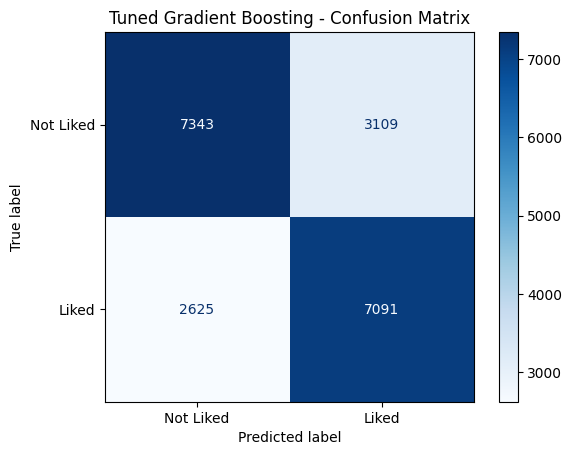

In [30]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, tuned_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Liked", "Liked"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Tuned Gradient Boosting - Confusion Matrix")
plt.show()

In [31]:
import joblib

joblib.dump(tuned_model, "movie_recommendation_model.pkl")

print("Model saved successfully!")

from google.colab import files
files.download("movie_recommendation_model.pkl")

Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

TOP 15 IMPORTANT FEATURES


,Feature,Importance
2,user_like_rate,0.5497
3,movie_avg_rating,0.2191
5,movie_like_rate,0.1255
0,user_avg_rating,0.0400
4,movie_rating_count,0.0265
1,user_rating_count,0.0206
13,Drama,0.0053
12,Documentary,0.0029
6,Action,0.0026
8,Animation,0.0015


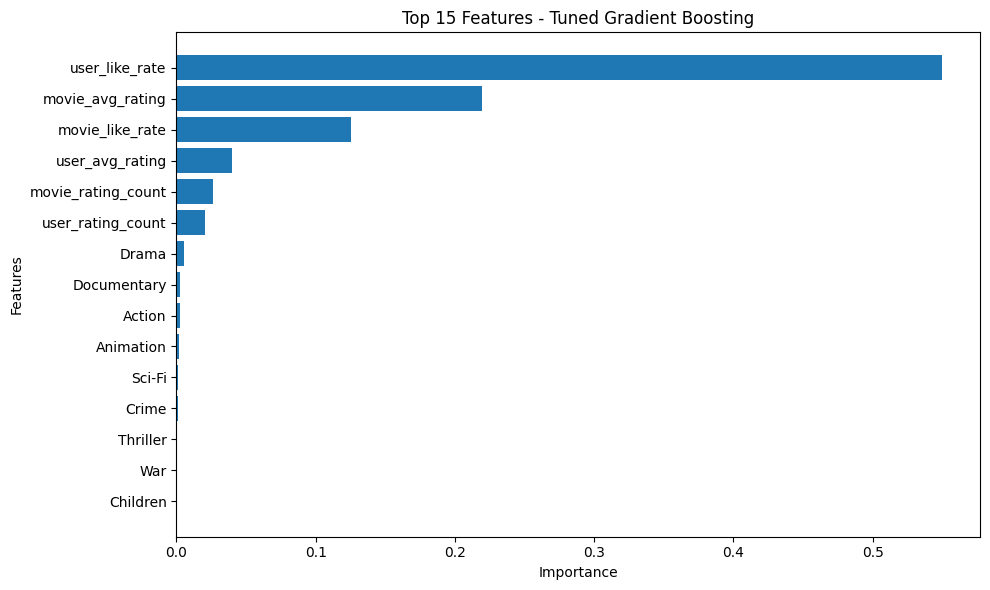

In [32]:
import pandas as pd
import matplotlib.pyplot as plt

feature_transformer = tuned_model.named_steps["features"]

gb_model = tuned_model.named_steps["model"]

feature_names = [
    "user_avg_rating",
    "user_rating_count",
    "user_like_rate",
    "movie_avg_rating",
    "movie_rating_count",
    "movie_like_rate"
] + genre_columns

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": gb_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("TOP 15 IMPORTANT FEATURES")
show_table(importance_df.head(15).round(4))

plt.figure(figsize=(10, 6))

top_features = importance_df.head(15).sort_values(
    by="Importance"
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Top 15 Features - Tuned Gradient Boosting")
plt.tight_layout()
plt.show()

In [35]:
print("MOVIE RECOMMENDATION SYSTEM - FINAL SUMMARY")

print("\nDataset Information")
print("Total ratings:", len(ratings_ml))
print("Total movies:", len(movies_ml))
print("Unique users:", ratings_ml["userId"].nunique())
print("Number of genres:", len(genre_columns))

print("\nBest Model: Tuned Gradient Boosting")

print("\nFinal Test Performance")
for metric in ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]:
    print(f"{metric}: {tuned_results[metric]:.4f}")

print("\nTop 5 Important Features")
print(importance_df.head(5).to_string(index=False))

print("\nModel saved as: movie_recommendation_model.pkl")

MOVIE RECOMMENDATION SYSTEM - FINAL SUMMARY

Dataset Information
Total ratings: 100836
Total movies: 9742
Unique users: 610
Number of genres: 19

Best Model: Tuned Gradient Boosting

Final Test Performance
Accuracy: 0.7157
Precision: 0.6952
Recall: 0.7298
F1 Score: 0.7121
ROC-AUC: 0.7901

Top 5 Important Features
           Feature  Importance
    user_like_rate    0.549657
  movie_avg_rating    0.219147
   movie_like_rate    0.125548
   user_avg_rating    0.039981
movie_rating_count    0.026542

Model saved as: movie_recommendation_model.pkl


In [36]:
from google.colab import files

files.download("ml-latest-small/movies.csv")
files.download("ml-latest-small/ratings.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:
!pip install -q streamlit pyngrok joblib scikit-learn pandas

In [38]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib

st.set_page_config(
    page_title="Movie Recommendation System",
    page_icon="🎬",
    layout="wide"
)

@st.cache_resource
def load_model():
    return joblib.load("movie_recommendation_model.pkl")

@st.cache_data
def load_data():
    movies = pd.read_csv("movies.csv")
    ratings = pd.read_csv("ratings.csv")
    return movies, ratings

model = load_model()
movies, ratings = load_data()

st.title("🎬 Movie Recommendation System")

st.write(
    "Discover movies using Machine Learning predictions "
    "based on user preferences."
)

page = st.sidebar.radio(
    "Navigation",
    ["Home", "Movie Recommendations", "Dataset Overview"]
)

if page == "Home":
    st.header("Welcome!")

    col1, col2, col3 = st.columns(3)

    col1.metric("Total Movies", len(movies))
    col2.metric("Total Ratings", len(ratings))
    col3.metric("Total Users", ratings["userId"].nunique())

elif page == "Movie Recommendations":
    st.header("Movie Recommendations")
    st.info("We will add personalized recommendations in the next step.")

elif page == "Dataset Overview":
    st.header("Movies Dataset")
    st.dataframe(movies.head(10))

    st.header("Ratings Dataset")
    st.dataframe(ratings.head(10))

Writing app.py


In [39]:
from google.colab import files

uploaded = files.upload()

Saving movie_recommendation_model.pkl to movie_recommendation_model (1).pkl
Saving movies.csv to movies.csv
Saving ratings.csv to ratings.csv


In [40]:
import os
import pandas as pd
import joblib

print("Files in Colab:")
print(os.listdir())

movies = pd.read_csv("movies.csv")
ratings = pd.read_csv("ratings.csv")

print("\nMovies shape:", movies.shape)
print("Ratings shape:", ratings.shape)

model_path = (
    "movie_recommendation_model (1).pkl"
    if os.path.exists("movie_recommendation_model (1).pkl")
    else "movie_recommendation_model.pkl"
)

model = joblib.load(model_path)

print("\nModel loaded successfully!")
print("Model file:", model_path)

Files in Colab:
['.config', 'movies.csv', 'ml-latest-small', 'movie_recommendation_model.pkl', 'app.py', 'ml-latest-small.zip', 'movie_recommendation_model (1).pkl', 'ratings.csv', 'sample_data']

Movies shape: (9742, 3)
Ratings shape: (100836, 4)

Model loaded successfully!
Model file: movie_recommendation_model (1).pkl


In [42]:
feature_transformer = model.named_steps["features"]

print("Transformer attributes:")
print(feature_transformer.__dict__.keys())

print("\nTransformer parameters:")
print(feature_transformer.get_params())

print("\nModel classes:")
print(model.classes_)

Transformer attributes:
dict_keys(['genre_columns', 'n_splits', 'random_state', 'user_stats_', 'movie_stats_', 'global_rating_', 'global_like_'])

Transformer parameters:
{'genre_columns': ['Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'IMAX', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western'], 'n_splits': 5, 'random_state': 42}

Model classes:
[0 1]


In [43]:
feature_transformer = model.named_steps["features"]

print("Genre columns:")
print(feature_transformer.genre_columns)

print("\nUser statistics:")
print(type(feature_transformer.user_stats_))
print(feature_transformer.user_stats_.head())

print("\nMovie statistics:")
print(type(feature_transformer.movie_stats_))
print(feature_transformer.movie_stats_.head())

print("\nGlobal rating:", feature_transformer.global_rating_)
print("Global like rate:", feature_transformer.global_like_)

Genre columns:
['Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'IMAX', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']

User statistics:
<class 'pandas.core.frame.DataFrame'>
        user_avg_rating  user_rating_count  user_like_rate
userId                                                    
1              4.340909                176        0.857955
2              3.900000                 25        0.600000
3              2.166667                 30        0.333333
4              3.630682                176        0.613636
5              3.625000                 32        0.531250

Movie statistics:
<class 'pandas.core.frame.DataFrame'>
         movie_avg_rating  movie_rating_count  movie_like_rate
movieId                                                       
1                3.914013                 157         0.675159
2                3.413043                  92         0.445652


In [45]:
from IPython.display import display as show_table

# Generate recommendations first
recommendations = recommend_movies(user_id=1, top_n=10)

print("Top 10 Movie Recommendations for User 1:")

# Display the results
show_table(recommendations)

Top 10 Movie Recommendations for User 1:


,title,genres,Like Probability
0,"Shawshank Redemption, The (1994)",Crime|Drama,0.962798
1,Sunset Blvd. (a.k.a. Sunset Boulevard) (1950),Drama|Film-Noir|Romance,0.944690
2,Miller's Crossing (1990),Crime|Drama|Film-Noir|Thriller,0.938183
3,Touch of Evil (1958),Crime|Film-Noir|Thriller,0.935729
4,"Big Sleep, The (1946)",Crime|Film-Noir|Mystery,0.934996
5,Paper Heart (2009),Comedy|Documentary|Drama|Romance,0.933481
6,Chinatown (1974),Crime|Film-Noir|Mystery|Thriller,0.933072
7,Titicut Follies (1967),Documentary|Drama,0.932877
8,Mulholland Drive (2001),Crime|Drama|Film-Noir|Mystery|Thriller,0.932509
9,Double Indemnity (1944),Crime|Drama|Film-Noir,0.931914


In [48]:
sample = movie_features.head(3).copy()
sample.insert(0, "userId", 1)

transformed = feature_transformer.transform(sample)

print("Transformed shape:", transformed.shape)
print("\nTransformed features:")
print(transformed)

Transformed shape: (3, 25)

Transformed features:
   user_avg_rating  user_rating_count  user_like_rate  movie_avg_rating  \
0         4.340909                176        0.857955          3.914013   
1         4.340909                176        0.857955          3.413043   
2         4.340909                176        0.857955          3.337838   

   movie_rating_count  movie_like_rate  Action  Adventure  Animation  \
0                 157         0.675159       0          1          1   
1                  92         0.445652       0          1          0   
2                  37         0.378378       0          0          0   

   Children  ...  Film-Noir  Horror  IMAX  Musical  Mystery  Romance  Sci-Fi  \
0         1  ...          0       0     0        0        0        0       0   
1         1  ...          0       0     0        0        0        0       0   
2         0  ...          0       0     0        0        0        1       0   

   Thriller  War  Western  
0         0

In [49]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib
import matplotlib.pyplot as plt

st.set_page_config(
    page_title="Movie Recommendation System",
    page_icon="🎬",
    layout="wide"
)

# Load files
@st.cache_resource
def load_model():
    return joblib.load("movie_recommendation_model (1).pkl")

@st.cache_data
def load_data():
    movies = pd.read_csv("movies.csv")
    ratings = pd.read_csv("ratings.csv")

    genres = movies["genres"].fillna("").str.get_dummies(sep="|")
    genres = genres.drop(
        columns=["(no genres listed)"],
        errors="ignore"
    )

    return movies, ratings, genres

model = load_model()
movies, ratings, genre_data = load_data()

feature_transformer = model.named_steps["features"]
genre_columns = feature_transformer.genre_columns

genre_data = genre_data.reindex(
    columns=genre_columns,
    fill_value=0
)

movie_features = pd.concat(
    [
        movies[["movieId"]].reset_index(drop=True),
        genre_data.reset_index(drop=True)
    ],
    axis=1
)

# Recommendation function
def recommend_movies(user_id, top_n=10):

    watched = ratings.loc[
        ratings["userId"] == user_id,
        "movieId"
    ].unique()

    candidates = movie_features[
        ~movie_features["movieId"].isin(watched)
    ].copy()

    candidates.insert(0, "userId", user_id)

    probabilities = model.predict_proba(candidates)[:, 1]

    candidates["Like Probability"] = probabilities

    results = candidates.nlargest(
        top_n, "Like Probability"
    )

    results = results.merge(
        movies[["movieId", "title", "genres"]],
        on="movieId",
        how="left"
    )

    results["Predicted Preference"] = (
        results["Like Probability"] * 100
    ).round(2).astype(str) + "%"

    return results[
        ["title", "genres", "Predicted Preference"]
    ]

# Sidebar
st.sidebar.title("🎬 Movie AI")
page = st.sidebar.radio(
    "Navigation",
    [
        "Home",
        "Movie Recommendations",
        "Dataset Overview",
        "Model Performance"
    ]
)

# Home
if page == "Home":

    st.title("Movie Recommendation System")

    st.write(
        "An end-to-end Machine Learning application "
        "that predicts movie preferences and recommends "
        "movies based on historical user ratings."
    )

    c1, c2, c3 = st.columns(3)

    c1.metric("Movies", len(movies))
    c2.metric("Ratings", len(ratings))
    c3.metric("Users", ratings["userId"].nunique())

    st.subheader("About the Project")

    st.write("""
    This application uses a tuned Gradient Boosting
    classifier to predict whether a user is likely
    to enjoy a movie.

    It also generates personalized Top 10 movie
    recommendations by ranking unseen movies.
    """)

# Recommendations
elif page == "Movie Recommendations":

    st.title("Personalized Recommendations")

    user_ids = sorted(ratings["userId"].unique())

    user_id = st.selectbox(
        "Select User ID",
        user_ids
    )

    top_n = st.slider(
        "Number of recommendations",
        5, 20, 10
    )

    if st.button("Generate Recommendations"):

        results = recommend_movies(user_id, top_n)

        st.subheader(f"Recommendations for User {user_id}")

        st.dataframe(
            results,
            use_container_width=True,
            hide_index=True
        )

# Dataset
elif page == "Dataset Overview":

    st.title("Dataset Overview")

    st.subheader("Movies")
    st.dataframe(movies.head(20), use_container_width=True)

    st.subheader("Ratings")
    st.dataframe(ratings.head(20), use_container_width=True)

    st.subheader("Rating Distribution")

    fig, ax = plt.subplots()
    ratings["rating"].value_counts().sort_index().plot(
        kind="bar", ax=ax
    )
    ax.set_xlabel("Rating")
    ax.set_ylabel("Number of Ratings")
    st.pyplot(fig)

# Performance
elif page == "Model Performance":

    st.title("Model Performance")

    metrics = pd.DataFrame({
        "Metric": [
            "Accuracy",
            "Precision",
            "Recall",
            "F1 Score",
            "ROC-AUC"
        ],
        "Score": [
            0.7157,
            0.6952,
            0.7298,
            0.7121,
            0.7901
        ]
    })

    st.dataframe(metrics, use_container_width=True)

    st.bar_chart(
        metrics.set_index("Metric")
    )

    st.subheader("Feature Importance")

    feature_names = (
        list(feature_transformer.transform(
            movie_features.head(1).assign(userId=1)
        ).columns)
    )

    importance = model.named_steps["model"].feature_importances_

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance
    }).sort_values("Importance", ascending=False)

    st.bar_chart(
        importance_df.head(10).set_index("Feature")
    )

st.sidebar.markdown("---")
st.sidebar.caption("Developed for Devixo Solutions ML Internship")

Overwriting app.py


In [50]:
!streamlit run app.py &>/content/streamlit.log &

In [51]:
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦
added 22 packages in 4s
⠦
⠦3 packages are looking for funding
⠦  run `npm fund` for details
⠦

In [52]:
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴⠦⠧⠇⠏your url is: https://dry-things-read.loca.lt
⠙

In [53]:
!cat /content/streamlit.log



2026-11-04 17:37:45.645 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.237.20.77:8501



In [54]:
!curl -I http://localhost:8501

HTTP/1.1 200 OK
date: Wed, 04 Nov 2026 17:40:03 GMT
server: uvicorn
content-type: text/html; charset=utf-8
accept-ranges: bytes
content-length: 6467
last-modified: Wed, 04 Nov 2026 17:29:14 GMT
etag: "a92f486fbe130323eb7d1cc0c7b977dd"
cache-control: no-cache



In [55]:
!lt --version

2.0.2


In [60]:
print("STREAMLIT LOGS")
!tail -n 60 /content/streamlit.log

print("\nSTREAMLIT HEALTH")
!curl -s http://localhost:8501/_stcore/health

print("\nAPP FILE")
!ls -lh app.py movie_recommendation_model\ \(1\).pkl movies.csv ratings.csv

STREAMLIT LOGS


2026-11-04 17:37:45.645 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.237.20.77:8501

  Stopping...

STREAMLIT HEALTH

APP FILE
-rw-r--r-- 1 root root 4.9K Nov  4 17:37  app.py
-rw-r--r-- 1 root root 570K Nov  4 17:29 'movie_recommendation_model (1).pkl'
-rw-r--r-- 1 root root 483K Nov  4 17:29  movies.csv
-rw-r--r-- 1 root root 2.4M Nov  4 17:29  ratings.csv


In [61]:
import subprocess
import time
import requests

# Stop any old Streamlit process
subprocess.run(["pkill", "-f", "streamlit"], capture_output=True)

time.sleep(2)

# Start Streamlit in a persistent background process
log_file = open("/content/streamlit.log", "w")

process = subprocess.Popen(
    [
        "python", "-m", "streamlit", "run", "app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

time.sleep(10)

print("Streamlit process ID:", process.pid)
print("Server response:")

try:
    response = requests.get(
        "http://localhost:8501/_stcore/health",
        timeout=10
    )
    print(response.status_code, response.text)
except Exception as e:
    print("Connection error:", e)

print("\nServer logs:")
print(open("/content/streamlit.log").read()[-3000:])

Streamlit process ID: 24900
Server response:
200 ok

Server logs:


2026-11-04 17:43:44.818 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.237.20.77:8501




In [62]:
!lt --port 8501

your url is: https://great-cars-burn.loca.lt


In [63]:
import subprocess
import time
import requests
import os

# Stop old Streamlit processes
subprocess.run(
    "pkill -f '[s]treamlit run'",
    shell=True
)

time.sleep(2)

# Start Streamlit again
log = open("/content/streamlit.log", "w")

process = subprocess.Popen(
    [
        "streamlit", "run", "app.py",
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.headless=true"
    ],
    stdout=log,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

time.sleep(8)

# Check server
try:
    response = requests.get(
        "http://127.0.0.1:8501/_stcore/health",
        timeout=5
    )
    print("Streamlit status:", response.status_code)
    print("Response:", response.text)
except Exception as error:
    print("Streamlit error:", error)

print("\nApplication logs:")
print(open("/content/streamlit.log").read()[-2000:])

Streamlit status: 200
Response: ok

Application logs:


2026-11-04 17:46:34.473 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.237.20.77:8501




In [64]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared

print("Cloudflare Tunnel installed successfully!")

Cloudflare Tunnel installed successfully!


In [69]:

%%writefile app.py

import streamlit as st
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, TransformerMixin

# IMPORTANT: Define custom transformer BEFORE loading model
class LeakageSafeMovieFeatures(BaseEstimator, TransformerMixin):

    def __init__(self, genre_columns=None, n_splits=5, random_state=42):
        self.genre_columns = genre_columns
        self.n_splits = n_splits
        self.random_state = random_state

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        # User statistics
        user_stats = self.user_stats_.reindex(X["userId"].values)

        # Movie statistics
        movie_stats = self.movie_stats_.reindex(X["movieId"].values)

        result = pd.DataFrame(index=X.index)

        result["user_avg_rating"] = (
            user_stats["user_avg_rating"].fillna(self.global_rating_).values
        )
        result["user_rating_count"] = (
            user_stats["user_rating_count"].fillna(0).values
        )
        result["user_like_rate"] = (
            user_stats["user_like_rate"].fillna(self.global_like_).values
        )

        result["movie_avg_rating"] = (
            movie_stats["movie_avg_rating"].fillna(self.global_rating_).values
        )
        result["movie_rating_count"] = (
            movie_stats["movie_rating_count"].fillna(0).values
        )
        result["movie_like_rate"] = (
            movie_stats["movie_like_rate"].fillna(self.global_like_).values
        )

        # Genre features
        for genre in self.genre_columns:
            if genre in X.columns:
                result[genre] = X[genre].fillna(0).values
            else:
                result[genre] = 0

        return result


# Load model and datasets
@st.cache_resource
def load_model():
    return joblib.load("movie_recommendation_model (1).pkl")

@st.cache_data
def load_data():
    movies = pd.read_csv("movies.csv")
    ratings = pd.read_csv("ratings.csv")
    return movies, ratings

model = load_model()
movies, ratings = load_data()

feature_transformer = model.named_steps["features"]
genre_columns = feature_transformer.genre_columns

# Prepare movie features
genre_data = movies["genres"].fillna("").str.get_dummies(sep="|")
genre_data = genre_data.drop(
    columns=["(no genres listed)"], errors="ignore"
)
genre_data = genre_data.reindex(
    columns=genre_columns, fill_value=0
)

movie_features = pd.concat(
    [movies[["movieId"]].reset_index(drop=True),
     genre_data.reset_index(drop=True)],
    axis=1
)

# Recommendation function
def recommend_movies(user_id, top_n=10):
    watched = ratings.loc[
        ratings["userId"] == user_id, "movieId"
    ].unique()

    candidates = movie_features[
        ~movie_features["movieId"].isin(watched)
    ].copy()

    candidates.insert(0, "userId", user_id)

    probabilities = model.predict_proba(candidates)[:, 1]
    candidates["Like Probability"] = probabilities

    results = candidates.nlargest(top_n, "Like Probability")

    results = results.merge(
        movies[["movieId", "title", "genres"]],
        on="movieId",
        how="left"
    )

    results["Predicted Preference"] = (
        results["Like Probability"] * 100
    ).round(2).astype(str) + "%"

    return results[
        ["title", "genres", "Predicted Preference"]
    ]


# Sidebar navigation
st.sidebar.title("🎬 Movie AI")

page = st.sidebar.radio(
    "Navigation",
    ["Home", "Movie Recommendations",
     "Dataset Overview", "Model Performance"]
)

# Home page
if page == "Home":
    st.title("🎬 Movie Recommendation System")
    st.write(
        "An end-to-end Machine Learning application "
        "that predicts movie preferences and recommends "
        "movies using historical user ratings."
    )

    c1, c2, c3 = st.columns(3)
    c1.metric("Total Movies", len(movies))
    c2.metric("Total Ratings", len(ratings))
    c3.metric("Total Users", ratings["userId"].nunique())

    st.subheader("About the Project")
    st.write(
        "This application uses a tuned Gradient Boosting "
        "classifier to predict movie preferences and generate "
        "personalized recommendations."
    )

# Recommendations page
elif page == "Movie Recommendations":
    st.title("🍿 Personalized Movie Recommendations")

    user_ids = sorted(ratings["userId"].unique())

    user_id = st.selectbox("Select User ID", user_ids)
    top_n = st.slider("Number of recommendations", 5, 20, 10)

    if st.button("Generate Recommendations"):
        results = recommend_movies(user_id, top_n)

        st.subheader(f"Recommendations for User {user_id}")
        st.dataframe(
            results,
            use_container_width=True,
            hide_index=True
        )

# Dataset page
elif page == "Dataset Overview":
    st.title("📊 Dataset Overview")

    st.subheader("Movies")
    st.dataframe(movies.head(20), use_container_width=True)

    st.subheader("Ratings")
    st.dataframe(ratings.head(20), use_container_width=True)

    st.subheader("Rating Distribution")
    fig, ax = plt.subplots()
    ratings["rating"].value_counts().sort_index().plot(
        kind="bar", ax=ax
    )
    ax.set_xlabel("Rating")
    ax.set_ylabel("Number of Ratings")
    st.pyplot(fig)

# Model performance page
elif page == "Model Performance":
    st.title("📈 Model Performance")

    metrics = pd.DataFrame({
        "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"],
        "Score": [0.7157, 0.6952, 0.7298, 0.7121, 0.7901]
    })

    st.dataframe(metrics, use_container_width=True)
    st.bar_chart(metrics.set_index("Metric"))

    st.subheader("Top 10 Feature Importance")

    importance = model.named_steps["model"].feature_importances_

    importance_df = pd.DataFrame({
        "Feature": feature_transformer.transform(
            movie_features.head(1).assign(userId=1)
        ).columns,
        "Importance": importance
    }).sort_values("Importance", ascending=False)

    st.bar_chart(
        importance_df.head(10).set_index("Feature")
    )

st.sidebar.markdown("---")
st.sidebar.caption("Devixo Solutions ML Internship")

Overwriting app.py


In [70]:
!pkill -f '[s]treamlit run' || true

In [71]:
import subprocess
import time
import requests

log = open("/content/streamlit.log", "w")

process = subprocess.Popen(
    [
        "streamlit", "run", "app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=log,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

time.sleep(10)

response = requests.get(
    "http://localhost:8501/_stcore/health"
)

print("Streamlit status:", response.status_code)
print(response.text)

Streamlit status: 200
ok


In [72]:
import subprocess
import time
import re
import os

# Start Cloudflare tunnel
with open("/content/cloudflare.log", "w") as log:
    tunnel = subprocess.Popen(
        [
            "./cloudflared", "tunnel",
            "--url", "http://localhost:8501",
            "--no-autoupdate"
        ],
        stdout=log,
        stderr=subprocess.STDOUT,
        start_new_session=True
    )

# Wait up to 40 seconds for URL
url = None

for _ in range(20):
    time.sleep(2)

    with open("/content/cloudflare.log") as f:
        logs = f.read()

    match = re.search(
        r"https://[a-zA-Z0-9-]+\.trycloudflare\.com",
        logs
    )

    if match:
        url = match.group(0)
        break

if url:
    print("YOUR LIVE APPLICATION:")
    print(url)
else:
    print("Cloudflare did not provide a URL.")
    print(logs[-3000:])

YOUR LIVE APPLICATION:
https://numbers-cia-product-qualify.trycloudflare.com


In [73]:
import os

print("App exists:", os.path.exists("app.py"))
print("Movies dataset exists:", os.path.exists("movies.csv"))
print("Ratings dataset exists:", os.path.exists("ratings.csv"))
print("Model exists:", os.path.exists("movie_recommendation_model (1).pkl"))

App exists: True
Movies dataset exists: True
Ratings dataset exists: True
Model exists: True


In [74]:
with open("app.py", "r") as f:
    print(f.read())


import streamlit as st
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, TransformerMixin

# IMPORTANT: Define custom transformer BEFORE loading model
class LeakageSafeMovieFeatures(BaseEstimator, TransformerMixin):

    def __init__(self, genre_columns=None, n_splits=5, random_state=42):
        self.genre_columns = genre_columns
        self.n_splits = n_splits
        self.random_state = random_state

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        # User statistics
        user_stats = self.user_stats_.reindex(X["userId"].values)

        # Movie statistics
        movie_stats = self.movie_stats_.reindex(X["movieId"].values)

        result = pd.DataFrame(index=X.index)

        result["user_avg_rating"] = (
            user_stats["user_avg_rating"].fillna(self.global_rating_).values
        )
        result["user_rating_count"] = (
            user_stats["user_rati

In [75]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import re
from sklearn.base import BaseEstimator, TransformerMixin


# Custom transformer must be defined before loading model
class LeakageSafeMovieFeatures(BaseEstimator, TransformerMixin):

    def __init__(self, genre_columns=None, n_splits=5, random_state=42):
        self.genre_columns = genre_columns
        self.n_splits = n_splits
        self.random_state = random_state

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        user_stats = self.user_stats_.reindex(X["userId"].values)
        movie_stats = self.movie_stats_.reindex(X["movieId"].values)

        result = pd.DataFrame(index=X.index)

        result["user_avg_rating"] = user_stats["user_avg_rating"].fillna(self.global_rating_).values
        result["user_rating_count"] = user_stats["user_rating_count"].fillna(0).values
        result["user_like_rate"] = user_stats["user_like_rate"].fillna(self.global_like_).values
        result["movie_avg_rating"] = movie_stats["movie_avg_rating"].fillna(self.global_rating_).values
        result["movie_rating_count"] = movie_stats["movie_rating_count"].fillna(0).values
        result["movie_like_rate"] = movie_stats["movie_like_rate"].fillna(self.global_like_).values

        for genre in self.genre_columns:
            result[genre] = X[genre].fillna(0).values if genre in X.columns else 0

        return result


# Load model and data
@st.cache_resource
def load_model():
    return joblib.load("movie_recommendation_model (1).pkl")

@st.cache_data
def load_data():
    return pd.read_csv("movies.csv"), pd.read_csv("ratings.csv")

model = load_model()
movies, ratings = load_data()

feature_transformer = model.named_steps["features"]
genre_columns = feature_transformer.genre_columns


# Prepare movie features
genre_data = movies["genres"].fillna("").str.get_dummies(sep="|")
genre_data = genre_data.drop(columns=["(no genres listed)"], errors="ignore")
genre_data = genre_data.reindex(columns=genre_columns, fill_value=0)

movie_features = pd.concat(
    [movies[["movieId"]].reset_index(drop=True),
     genre_data.reset_index(drop=True)], axis=1
)


# Extract release year
def get_year(title):
    match = re.search(r"\((\d{4})\)\s*$", str(title))
    return match.group(1) if match else "Unknown"

movies["Year"] = movies["title"].apply(get_year)


# Recommendation function
def recommend_movies(user_id, top_n=10, selected_genre="All"):
    watched = ratings.loc[
        ratings["userId"] == user_id, "movieId"
    ].unique()

    candidates = movie_features[
        ~movie_features["movieId"].isin(watched)
    ].copy()

    if selected_genre != "All":
        candidates = candidates[
            candidates[selected_genre] == 1
        ]

    if candidates.empty:
        return pd.DataFrame()

    candidates.insert(0, "userId", user_id)
    candidates["Like Score"] = model.predict_proba(candidates)[:, 1]

    results = candidates.nlargest(top_n, "Like Score")

    results = results.merge(
        movies[["movieId", "title", "genres", "Year"]],
        on="movieId", how="left"
    )

    results["Predicted Preference"] = (
        results["Like Score"] * 100
    ).round(2).astype(str) + "%"

    return results[
        ["title", "Year", "genres", "Predicted Preference"]
    ].rename(columns={
        "title": "Movie",
        "Year": "Release Year",
        "genres": "Genres"
    })


# Sidebar navigation
st.sidebar.title("🎬 Movie AI")

page = st.sidebar.radio(
    "Navigation",
    ["Home", "Movie Recommendations", "Movie Search",
     "Dataset Overview", "Model Performance"]
)


# HOME
if page == "Home":
    st.title("🎬 Movie Recommendation System")
    st.write(
        "An end-to-end Machine Learning application that predicts "
        "movie preferences and recommends movies using historical ratings."
    )

    c1, c2, c3 = st.columns(3)
    c1.metric("Total Movies", len(movies))
    c2.metric("Total Ratings", len(ratings))
    c3.metric("Total Users", ratings["userId"].nunique())

    st.subheader("About the Project")
    st.write(
        "The application uses a tuned Gradient Boosting classifier "
        "to predict movie preferences and generate personalized recommendations."
    )

    st.info("Explore movie recommendations, search movies, and view model performance using the sidebar.")


# RECOMMENDATIONS
elif page == "Movie Recommendations":
    st.title("🍿 Personalized Movie Recommendations")

    user_ids = sorted(ratings["userId"].unique())
    user_id = st.selectbox("Select User ID", user_ids)

    col1, col2 = st.columns(2)

    with col1:
        top_n = st.slider("Number of recommendations", 5, 20, 10)

    with col2:
        selected_genre = st.selectbox(
            "Filter by genre", ["All"] + genre_columns
        )

    if st.button("Generate Recommendations"):
        results = recommend_movies(user_id, top_n, selected_genre)

        if results.empty:
            st.warning("No movies found for this selection.")
        else:
            st.subheader(f"Recommendations for User {user_id}")
            st.dataframe(results, use_container_width=True, hide_index=True)
            st.caption("Preference scores are model predictions, not guaranteed outcomes.")


# MOVIE SEARCH
elif page == "Movie Search":
    st.title("🔎 Search Movies")

    search = st.text_input("Enter a movie title")

    if search:
        matches = movies[
            movies["title"].str.contains(search, case=False, na=False)
        ]

        st.write(f"Found {len(matches)} movies.")

        if not matches.empty:
            st.dataframe(
                matches[["title", "Year", "genres"]].head(50),
                use_container_width=True,
                hide_index=True
            )
        else:
            st.warning("No matching movies found.")


# DATASET
elif page == "Dataset Overview":
    st.title("📊 Dataset Overview")

    st.subheader("Movies")
    st.dataframe(movies.head(20), use_container_width=True)

    st.subheader("Ratings")
    st.dataframe(ratings.head(20), use_container_width=True)

    st.subheader("Rating Distribution")
    fig, ax = plt.subplots()
    ratings["rating"].value_counts().sort_index().plot(kind="bar", ax=ax)
    ax.set_xlabel("Rating")
    ax.set_ylabel("Number of Ratings")
    st.pyplot(fig)
    plt.close(fig)


# MODEL PERFORMANCE
elif page == "Model Performance":
    st.title("📈 Model Performance")

    metrics = pd.DataFrame({
        "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"],
        "Score": [0.7157, 0.6952, 0.7298, 0.7121, 0.7901]
    })

    st.dataframe(metrics, use_container_width=True)
    st.bar_chart(metrics.set_index("Metric"))

    st.subheader("Top 10 Feature Importance")

    importance = model.named_steps["model"].feature_importances_

    importance_df = pd.DataFrame({
        "Feature": feature_transformer.transform(
            movie_features.head(1).assign(userId=1)
        ).columns,
        "Importance": importance
    }).sort_values("Importance", ascending=False)

    st.bar_chart(importance_df.head(10).set_index("Feature"))


st.sidebar.markdown("---")
st.sidebar.caption("Devixo Solutions ML Internship")

Overwriting app.py


In [76]:
!pkill -f "streamlit run app.py" || true

^C


In [77]:
!streamlit run app.py &>/content/streamlit.log &

In [78]:
import requests
import time

time.sleep(3)
print("Streamlit status:", requests.get("http://localhost:8501/_stcore/health").status_code)

Streamlit status: 200


In [79]:
%%writefile README.md

# Movie Preference Prediction and Recommendation System

**Devixo Solutions – Machine Learning Internship**
**Task 04: End-to-End ML Application with Deployment**

## 1. Project Overview

This project is an end-to-end Machine Learning application that predicts movie preferences using historical user ratings and recommends movies that users have not watched or rated before.

The application is developed using Python, Scikit-learn, Pandas, Joblib, and Streamlit.

## 2. Dataset

Dataset: MovieLens Latest-Small

- Total Movies: 9,742
- Total Ratings: 100,836
- Total Users: 610

Files:
- movies.csv
- ratings.csv

Ratings are converted into binary labels:
- Rating >= 4.0: Liked (1)
- Rating < 4.0: Not Liked (0)

## 3. Machine Learning Models

Four classification algorithms were trained and compared:

1. Logistic Regression
2. K-Nearest Neighbors
3. Random Forest
4. Gradient Boosting

Gradient Boosting was selected and optimized using RandomizedSearchCV.

## 4. Final Model Performance

| Metric | Score |
|---|---:|
| Accuracy | 71.57% |
| Precision | 69.52% |
| Recall | 72.98% |
| F1 Score | 71.21% |
| ROC-AUC | 79.01% |

## 5. Application Features

### Home
Displays project information and dataset statistics.

### Movie Recommendations
- Select an existing user.
- Choose the number of recommendations.
- Filter recommendations by genre.
- View predicted preference scores.

### Movie Search
Search movies by title and view release year and genres.

### Dataset Overview
Explore movie and rating records and rating distribution.

### Model Performance
View evaluation metrics and feature importance.

## 6. Technologies Used

- Python
- Pandas
- NumPy
- Scikit-learn
- Matplotlib
- Joblib
- Streamlit

## 7. Project Files

```text
Movie-Recommendation-System/
├── app.py
├── movie_recommendation_model (1).pkl
├── movies.csv
├── ratings.csv
├── requirements.txt
└── README.md

Writing README.md


In [81]:
import sklearn

requirements = f"""streamlit
pandas
numpy
scikit-learn=={sklearn.__version__}
joblib
matplotlib
"""

with open("/content/requirements.txt", "w") as file:
    file.write(requirements)

print("requirements.txt created successfully!")
print(requirements)

requirements.txt created successfully!
streamlit
pandas
numpy
scikit-learn==1.6.1
joblib
matplotlib



In [82]:
!ls -l /content/requirements.txt

-rw-r--r-- 1 root root 61 Nov  4 18:03 /content/requirements.txt


In [83]:
!pip -q install python-docx

In [84]:
from docx import Document
from docx.shared import Inches, Pt
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.table import WD_TABLE_ALIGNMENT
from docx.oxml import OxmlElement
from docx.oxml.ns import qn

doc = Document()

# Page formatting
section = doc.sections[0]
section.top_margin = Inches(0.7)
section.bottom_margin = Inches(0.7)
section.left_margin = Inches(0.8)
section.right_margin = Inches(0.8)

doc.styles["Normal"].font.name = "Arial"
doc.styles["Normal"].font.size = Pt(10)

# Cover page
p = doc.add_paragraph()
p.alignment = WD_ALIGN_PARAGRAPH.CENTER
r = p.add_run("\n\nPROJECT REPORT\n\n")
r.bold = True
r.font.size = Pt(18)

p = doc.add_paragraph()
p.alignment = WD_ALIGN_PARAGRAPH.CENTER
r = p.add_run("MOVIE PREFERENCE PREDICTION\nAND RECOMMENDATION SYSTEM")
r.bold = True
r.font.size = Pt(22)

p = doc.add_paragraph()
p.alignment = WD_ALIGN_PARAGRAPH.CENTER
p.add_run(
    "\nDevixo Solutions\n"
    "Machine Learning Internship\n"
    "Task 04: End-to-End ML Application with Deployment\n\n"
    "Dataset: MovieLens Latest-Small\n"
    "Technology: Python, Scikit-learn, Streamlit"
)

doc.add_page_break()

def heading(text):
    doc.add_heading(text, level=1)

def bullet(text):
    doc.add_paragraph(text, style="List Bullet")

def number(text):
    doc.add_paragraph(text, style="List Number")

heading("1. Introduction")
doc.add_paragraph(
    "The Movie Preference Prediction and Recommendation System is an "
    "end-to-end machine learning project developed as part of the Devixo "
    "Solutions Machine Learning Internship. The system analyzes historical "
    "movie ratings to predict whether a user is likely to enjoy a movie. "
    "It then recommends movies that the selected user has not previously rated. "
    "The trained machine learning model is integrated into an interactive "
    "Streamlit application."
)

heading("2. Project Objectives")
for item in [
    "Understand and preprocess a real-world movie ratings dataset.",
    "Perform feature engineering and prepare data for machine learning.",
    "Train and compare at least four classification algorithms.",
    "Apply hyperparameter tuning to improve model performance.",
    "Evaluate the final model using classification metrics.",
    "Save the trained model using Joblib.",
    "Develop an interactive application using Streamlit."
]:
    bullet(item)

heading("3. Dataset Description")
doc.add_paragraph(
    "The project uses the MovieLens Latest-Small dataset, which contains "
    "movie information and historical ratings provided by users."
)

table = doc.add_table(rows=1, cols=2)
table.style = "Table Grid"
table.alignment = WD_TABLE_ALIGNMENT.CENTER
table.rows[0].cells[0].text = "Dataset Information"
table.rows[0].cells[1].text = "Count"

for a, b in [
    ("Movies", "9,742"),
    ("Ratings", "100,836"),
    ("Unique Users", "610")
]:
    cells = table.add_row().cells
    cells[0].text = a
    cells[1].text = b

doc.add_paragraph(
    "The ratings were converted into binary preference labels. Ratings "
    "of 4.0 or higher were classified as Liked (1), while ratings below "
    "4.0 were classified as Not Liked (0). Movie genres were encoded "
    "into binary features."
)

heading("4. Data Preprocessing and Feature Engineering")
for item in [
    "Loaded the movies.csv and ratings.csv files.",
    "Prepared a binary target variable from numerical ratings.",
    "Encoded movie genres using one-hot encoding.",
    "Split the data into 80% training and 20% testing sets using stratification.",
    "Generated user statistics, including average rating, rating count, and like rate.",
    "Generated movie statistics, including average rating, rating count, and like rate.",
    "Used out-of-fold statistics during training feature generation to reduce target leakage."
]:
    number(item)

heading("5. Machine Learning Models")
doc.add_paragraph(
    "Four classification algorithms were trained and evaluated to identify "
    "the most suitable model for predicting movie preferences."
)

for item in [
    "Logistic Regression",
    "K-Nearest Neighbors (KNN)",
    "Random Forest",
    "Gradient Boosting"
]:
    bullet(item)

doc.add_paragraph(
    "Gradient Boosting was selected for further optimization because it "
    "provided the strongest overall results among the initial models."
)

heading("6. Hyperparameter Tuning")
doc.add_paragraph(
    "RandomizedSearchCV was applied to the Gradient Boosting classifier "
    "using cross-validation and F1-score as the optimization metric. "
    "The tuned model was evaluated on the held-out test set."
)

heading("7. Final Model Performance")
doc.add_paragraph(
    "The tuned Gradient Boosting classifier achieved the following "
    "evaluation results on the test dataset:"
)

table = doc.add_table(rows=1, cols=2)
table.style = "Table Grid"
table.alignment = WD_TABLE_ALIGNMENT.CENTER
table.rows[0].cells[0].text = "Metric"
table.rows[0].cells[1].text = "Score"

for a, b in [
    ("Accuracy", "71.57%"),
    ("Precision", "69.52%"),
    ("Recall", "72.98%"),
    ("F1-score", "71.21%"),
    ("ROC-AUC", "79.01%")
]:
    cells = table.add_row().cells
    cells[0].text = a
    cells[1].text = b

doc.add_paragraph(
    "Hyperparameter tuning resulted in a small improvement over the "
    "original Gradient Boosting model. The F1-score increased from "
    "0.7105 to 0.7121, while ROC-AUC increased from 0.7891 to 0.7901."
)

heading("8. Model Saving")
doc.add_paragraph(
    "The final tuned Gradient Boosting pipeline was saved using Joblib "
    "in a pickle file. The Streamlit application loads this saved model "
    "to generate predictions without retraining the model every time "
    "the application starts."
)

heading("9. Streamlit Application")
doc.add_paragraph(
    "An interactive web application was developed using Streamlit. "
    "It provides the following sections:"
)

for a, b in [
    ("Home", "Displays the project introduction and dataset statistics."),
    ("Movie Recommendations", "Allows users to select an existing MovieLens User ID, choose the number of recommendations, filter by genre, and view predicted preference scores."),
    ("Movie Search", "Allows users to search movies by title and view release year and genres."),
    ("Dataset Overview", "Displays movie and rating samples and a rating distribution chart."),
    ("Model Performance", "Displays evaluation metrics and feature importance.")
]:
    p = doc.add_paragraph()
    r = p.add_run(a + ": ")
    r.bold = True
    p.add_run(b)

heading("10. How to Run the Application")
doc.add_paragraph(
    "The following files must be placed in the same project directory:"
)
for item in [
    "app.py",
    "movie_recommendation_model (1).pkl",
    "movies.csv",
    "ratings.csv",
    "requirements.txt"
]:
    bullet(item)

doc.add_paragraph("Install the required libraries:")
p = doc.add_paragraph()
r = p.add_run("pip install -r requirements.txt")
r.font.name = "Consolas"

doc.add_paragraph("Start the Streamlit application:")
p = doc.add_paragraph()
r = p.add_run("streamlit run app.py")
r.font.name = "Consolas"

doc.add_paragraph(
    "The application can then be accessed through the local URL displayed "
    "by Streamlit. The model filename used in app.py must match the actual "
    "model file."
)

heading("11. Limitations")
for item in [
    "The current recommendation system supports existing MovieLens users with historical ratings.",
    "New users without rating history cannot yet receive fully personalized recommendations.",
    "Prediction scores are model scores and are not guaranteed probabilities of user satisfaction.",
    "The application uses a relatively small public dataset and is an internship prototype.",
    "A successful local application run does not by itself establish permanent public deployment."
]:
    bullet(item)

heading("12. Future Improvements")
for item in [
    "Add a new-user onboarding feature using selected genres or initial movie ratings.",
    "Integrate movie posters and additional movie information.",
    "Add user accounts and saved preferences.",
    "Evaluate recommendations using Precision@K, Recall@K, and NDCG.",
    "Deploy the application to a public cloud hosting platform."
]:
    bullet(item)

heading("13. Conclusion")
doc.add_paragraph(
    "This project demonstrates an end-to-end machine learning workflow, "
    "including data preprocessing, feature engineering, model training, "
    "model comparison, hyperparameter tuning, evaluation, model saving, "
    "and application development. The final tuned Gradient Boosting model "
    "is integrated into a Streamlit application that provides personalized "
    "movie recommendations for existing MovieLens users, movie search, "
    "dataset exploration, and model performance information. The result "
    "is an interactive machine learning application rather than only a "
    "Jupyter Notebook."
)

# Footer
for section in doc.sections:
    footer = section.footer.paragraphs[0]
    footer.alignment = WD_ALIGN_PARAGRAPH.CENTER
    footer.add_run("Devixo Solutions | Machine Learning Internship")

doc.save("/content/Project_Report.docx")

print("Word report created successfully!")

Word report created successfully!


In [85]:
from google.colab import files

files.download("/content/Project_Report.docx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [86]:
files.download("/content/README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [87]:
pip install -r requirements.txt